# Beyond Access
## Which Complaints Get Missed? A Sentiment Audit of Bay Area Healthcare Reviews

This notebook studies Google Maps reviews of healthcare services in the nine counties of the San Francisco Bay Area. It asks two related questions.

**A. Which feedback makes it into the review sample we can read?** For the same set of places, we compare the share of low-star reviews among the sampled review texts with the share of low-star ratings in each place's full rating distribution.

**B. Which feedback does a general-purpose text model miss?** We train a text classifier on a general Google Maps review file, evaluate it on Bay Area healthcare reviews, and compare its errors across seven service groups.

The model reads review text and predicts **low-star** (1–2 stars) versus **other** (3–5 stars). Three-star reviews often describe a mixed experience, so "other" does not mean positive. A **miss** is a review that received 1–2 stars but that the model labels "other".

Star ratings are a checkable proxy for expressed dissatisfaction. They do not measure clinical quality or patient safety, and this notebook does not rank providers.

**Status:** Sections 1–4 are implemented. Sections 5–7 describe planned work and contain no results yet.

## 1. Setup and inputs

The analysis uses two full CSV files supplied by the organizers, read from a local `data/` folder.

- `google_maps_reviews.csv` (Reviews): one row per review, covering many kinds of businesses in and outside the Bay Area. It will be the training source for the text model.
- `google_maps.csv` (Places): one row per place listing, with coordinates, a primary category, a nested sample of reviews (`top_reviews`) and the full star distribution (`review_distribution`). It is the source for the Bay Area healthcare analysis.

The organizers' small preview file is not used. Raw files stay local and are not committed.

In [1]:
import hashlib
import json
import warnings
from collections import Counter
from pathlib import Path
from urllib.parse import quote, urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.path import Path as PolygonPath
from matplotlib.ticker import PercentFormatter

RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
REVIEWS_PATH = DATA_DIR / "google_maps_reviews.csv"
PLACES_PATH = DATA_DIR / "google_maps.csv"

for path in (REVIEWS_PATH, PLACES_PATH):
    assert path.exists(), f"Missing input file: {path.relative_to(ROOT)}"

## 2. Data checks

Before any filtering, we confirm that the two files have the keys and labels the design depends on. Only counts and field names are shown here, never review text or reviewer details.

In [2]:
# Reviews: keep IDs and ratings, and reduce the text to a has-text flag so the full text never stays in memory.
review_chunks = []
for chunk in pd.read_csv(
    REVIEWS_PATH,
    usecols=["place_id", "review_id", "review_rating", "review"],
    chunksize=50_000,
):
    chunk["has_text"] = chunk["review"].fillna("").astype(str).str.strip().ne("")
    review_chunks.append(chunk.drop(columns="review"))
reviews = pd.concat(review_chunks, ignore_index=True)

rating = pd.to_numeric(reviews["review_rating"], errors="coerce")
is_zero_rating = rating.eq(0)
is_valid_rating = rating.isin([1, 2, 3, 4, 5])

In [3]:
# Places: the listing ID must be unique for it to work as a key, and every listing needs coordinates for the county filter.
places = pd.read_csv(PLACES_PATH, usecols=["place_id", "lat", "lon"])

# Exact place_id intersection between the two files.
in_places = reviews["place_id"].isin(places["place_id"])

In [4]:
checks = [
    ("Reviews", "Rows", len(reviews)),
    ("Reviews", "Unique place_id", reviews["place_id"].nunique()),
    ("Reviews", "Duplicate review_id", int(reviews["review_id"].duplicated().sum())),
    ("Reviews", "Rating = 0", int(is_zero_rating.sum())),
    ("Reviews", "Rating 1-5", int(is_valid_rating.sum())),
    ("Reviews", "Rating missing or other value", int((~is_zero_rating & ~is_valid_rating).sum())),
    ("Reviews", "Rating 1-5 with missing or blank text", int((is_valid_rating & ~reviews["has_text"]).sum())),
    ("Reviews", "Rating 1-5 with text", int((is_valid_rating & reviews["has_text"]).sum())),
    ("Places", "Rows", len(places)),
    ("Places", "Duplicate place_id", int(places["place_id"].duplicated().sum())),
    ("Places", "Missing lat or lon", int(places[["lat", "lon"]].isna().any(axis=1).sum())),
    ("Both", "Reviews with a place_id found in Places", int(in_places.sum())),
    ("Both", "Places in that intersection", reviews.loc[in_places, "place_id"].nunique()),
]
check_table = pd.DataFrame(checks, columns=["File", "Check", "Count"])
check_table.assign(Count=check_table["Count"].map("{:,}".format))

,File,Check,Count
0,Reviews,Rows,"213,536"
1,Reviews,Unique place_id,"6,108"
2,Reviews,Duplicate review_id,0
3,Reviews,Rating = 0,"42,184"
4,Reviews,Rating 1-5,"171,352"
5,Reviews,Rating missing or other value,0
6,Reviews,Rating 1-5 with missing or blank text,8
7,Reviews,Rating 1-5 with text,"171,344"
8,Places,Rows,"147,429"
9,Places,Duplicate place_id,0


Both keys behave as expected: `review_id` is unique in Reviews, `place_id` is unique in Places, and every listing has coordinates. About one in five Reviews rows has a rating of 0. Its meaning is unconfirmed, so those rows are set aside rather than treated as low-star, which leaves 171,344 reviews with a 1–5 rating and text as training candidates.

Only 2,985 reviews (1.4% of Reviews) share a `place_id` with Places, across 139 listings. That is too small to build the project on an inner join, so the files are combined by role instead: Reviews trains the model, and the rated reviews nested in Places provide the healthcare evaluation data. The exact key is still used to keep overlapping places out of training.

In [5]:
# Structure of the two nested Places fields, from the first 5,000 listings. Only field names are printed.
nested = pd.read_csv(PLACES_PATH, usecols=["top_reviews", "review_distribution"], nrows=5_000)

top_review_keys = Counter()
for raw in nested["top_reviews"].dropna():
    for entry in json.loads(raw):
        top_review_keys.update(entry.keys())

distribution_keys = Counter()
for raw in nested["review_distribution"].dropna():
    distribution_keys.update(json.loads(raw).keys())

print("top_reviews entry fields:", sorted(top_review_keys))
print("review_distribution fields:", sorted(distribution_keys))

top_reviews entry fields: ['content', 'rating', 'review_date', 'reviewer_image_url', 'reviewer_name', 'reviewer_photos_number', 'reviewer_reviews_number']
review_distribution fields: ['1_star_reviews', '2_star_reviews', '3_star_reviews', '4_star_reviews', '5_star_reviews']


In these first 5,000 listings, each `top_reviews` entry carries the review text (`content`), a star `rating` and a `review_date`, which is what the evaluation set needs. The reviewer fields will not be extracted. `review_distribution` holds one count per star level; Section 4 will require all five counts to be numeric with a positive sum before a place is used.

## 3. Nine-county healthcare cohort

This section builds the evaluation cohort: reviews nested in Places listings that sit inside the nine Bay Area counties and whose primary category belongs to one of seven healthcare service groups. The unit is a Google place listing. A hospital, one of its departments and an individual practitioner can each have their own listing, sometimes at the same address, and they are kept as separate listings.

### County boundaries

Counties are assigned from listing coordinates with a point-in-polygon test against U.S. Census TIGERweb county polygons. The query below selects the nine counties by GEOID and asks for longitude, latitude coordinates in EPSG:4326. The response is cached in `data/`. If the cache is missing it is downloaded again, and a hash of the geometry is compared with the copy retrieved on 2026-11-14, so a changed boundary is reported instead of passing unnoticed. The service does not return a version label.

In [6]:
TIGERWEB_URL = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/State_County/MapServer/1/query"
BAY_AREA_COUNTIES = {
    "06001": "Alameda", "06013": "Contra Costa", "06041": "Marin",
    "06055": "Napa", "06075": "San Francisco", "06081": "San Mateo",
    "06085": "Santa Clara", "06095": "Solano", "06097": "Sonoma",
}
TIGERWEB_PARAMS = {
    "where": "GEOID IN ({})".format(",".join(f"'{geoid}'" for geoid in BAY_AREA_COUNTIES)),
    "outFields": "GEOID,NAME",
    "returnGeometry": "true",
    "outSR": "4326",
    "maxAllowableOffset": "0.0001",
    "f": "geojson",
}
BOUNDARY_PATH = DATA_DIR / "tigerweb_bay_area_counties.geojson"
BOUNDARY_SHA256 = "6d6b96dd1c0b364716c13a19c1fee79b004b37f6d0cb4a1cfaa07b7e2efff6db"

if not BOUNDARY_PATH.exists():
    query_url = f"{TIGERWEB_URL}?{urlencode(TIGERWEB_PARAMS, quote_via=quote)}"
    with urlopen(query_url, timeout=60) as response:
        BOUNDARY_PATH.write_bytes(response.read())

county_features = sorted(
    json.loads(BOUNDARY_PATH.read_text(encoding="utf-8"))["features"],
    key=lambda feature: feature["properties"]["GEOID"],
)
returned_geoids = [feature["properties"]["GEOID"] for feature in county_features]
assert returned_geoids == sorted(BAY_AREA_COUNTIES), "The boundary file does not hold exactly the nine counties"

# Hash the geometry in a fixed order so feature order or whitespace in the response cannot change the result.
canonical_boundaries = json.dumps(
    [{"GEOID": f["properties"]["GEOID"], "geometry": f["geometry"]} for f in county_features],
    sort_keys=True,
    separators=(",", ":"),
)
if hashlib.sha256(canonical_boundaries.encode()).hexdigest() != BOUNDARY_SHA256:
    warnings.warn("County boundaries differ from the copy retrieved on 2026-11-14. County counts below may change.")

In [7]:
def points_in_geometry(points, geometry):
    """Test (lon, lat) points against a GeoJSON Polygon or MultiPolygon, treating inner rings as holes."""
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    inside = np.zeros(len(points), dtype=bool)
    for exterior, *holes in polygons:
        in_polygon = PolygonPath(exterior).contains_points(points)
        for hole in holes:
            in_polygon &= ~PolygonPath(hole).contains_points(points)
        inside |= in_polygon
    return inside


listing_points = places[["lon", "lat"]].to_numpy()
in_county = np.column_stack([points_in_geometry(listing_points, f["geometry"]) for f in county_features])

# Boundaries are simplified to about 11 m, so neighbouring polygons could overlap slightly. Stop if any listing matches two.
assert in_county.sum(axis=1).max() <= 1, "A listing falls inside more than one county"

county_names = np.array([BAY_AREA_COUNTIES[geoid] for geoid in returned_geoids])
places["county"] = pd.Series(county_names[in_county.argmax(axis=1)], index=places.index).where(in_county.any(axis=1))

No listing matched more than one county. A point lying exactly on a county line gets no special rule and falls on whichever side the polygon test puts it. Listings outside all nine polygons are dropped.

### Service groups and name screen

Listings are grouped by their primary category, matched as a complete name after trimming and case-folding. The seven groups are mutually exclusive and define the study scope. They do not cover every medical specialty. Open and closed listings are both kept, because the reviews describe past visits.

A primary category can still include listings that are plainly not human healthcare, so a narrow name screen removes veterinary services and medical spas. Broader words such as "cosmetic", "aesthetic" or "spa" are not used, because most of those names are ordinary dental practices.

In [8]:
SERVICE_GROUPS = {
    "Outpatient & primary care": [
        "Doctor", "Family practice physician", "Internist", "Medical clinic", "Clinic",
        "Walk-in clinic", "Community health center", "Pediatrician", "Pediatric clinic",
    ],
    "Dental care": ["Dentist", "Dental clinic", "Pediatric dentist", "Emergency dental service"],
    "Mental health": [
        "Psychologist", "Psychotherapist", "Psychiatrist", "Mental health clinic",
        "Mental health service", "Mental health services", "Child psychologist", "Child psychiatrist",
    ],
    "Pharmacy": ["Pharmacy"],
    "Hospital & urgent care": [
        "Hospital", "General hospital", "Urgent care center", "Emergency room", "Children's hospital",
    ],
    "Vision care": ["Optometrist", "Eye care center", "Ophthalmology clinic"],
    "Physical rehabilitation": ["Physical therapist", "Physical therapy clinic"],
}
CATEGORY_TO_GROUP = {
    category.casefold(): group for group, categories in SERVICE_GROUPS.items() for category in categories
}
assert len(CATEGORY_TO_GROUP) == sum(len(categories) for categories in SERVICE_GROUPS.values())

# Name screen. "Vet Center" is excluded from the veterinary pattern because it is a veterans' counseling service.
VETERINARY_NAME = r"\bveterinar|\bpets?\b|\banimal (?:hospital|shelter)\b|\bequine dentistry\b|\bhorse dentist\b|\bvet\b(?! center)"
MED_SPA_NAME = r"\bmed[\s-]?spa\b|\bmedi[\s-]?spa\b|\bmedical spa\b"

In [9]:
# Filter at the listing level first, so the nested reviews are only parsed for listings in scope.
county_by_place = places.set_index("place_id")["county"].dropna()

listing_chunks = []
for chunk in pd.read_csv(
    PLACES_PATH,
    usecols=["place_id", "name", "category", "top_reviews", "review_distribution"],
    chunksize=20_000,
):
    chunk["county"] = chunk["place_id"].map(county_by_place)
    chunk["service_group"] = chunk["category"].str.strip().str.casefold().map(CATEGORY_TO_GROUP)
    listing_chunks.append(chunk[chunk["county"].notna() & chunk["service_group"].notna()])
in_scope_listings = pd.concat(listing_chunks, ignore_index=True)

listing_names = in_scope_listings["name"].fillna("")
is_screened_out = (
    listing_names.str.contains(VETERINARY_NAME, case=False, regex=True)
    | listing_names.str.contains(MED_SPA_NAME, case=False, regex=True)
)
listings = in_scope_listings[~is_screened_out].reset_index(drop=True)

### Reviews

Each nested review contributes only its text, star rating and date. Reviewer fields are never read into the table. A review is usable if its rating is 1–5 and its text is not blank. The original text is kept for modeling, and a separate key (trimmed, case-folded) is used for duplicate checks.

In [10]:
malformed = Counter()
nested_rows = []
for place_id, raw in zip(listings["place_id"], listings["top_reviews"]):
    if pd.isna(raw):
        continue
    try:
        entries = json.loads(raw)
    except ValueError:
        entries = None
    if not isinstance(entries, list):
        malformed["top_reviews fields that are not a JSON list"] += 1
        continue
    for entry in entries:
        if not isinstance(entry, dict):
            malformed["entries that are not JSON objects"] += 1
            entry = {}
        nested_rows.append((place_id, entry.get("content"), entry.get("rating"), entry.get("review_date")))
nested_reviews = pd.DataFrame(nested_rows, columns=["place_id", "text", "rating", "review_date"])

has_valid_rating = nested_reviews["rating"].map(
    lambda value: isinstance(value, (int, float)) and not isinstance(value, bool) and value in (1, 2, 3, 4, 5)
)
has_text = nested_reviews["text"].map(lambda value: isinstance(value, str) and value.strip() != "")

usable_reviews = nested_reviews[has_valid_rating & has_text].copy()
usable_reviews["rating"] = usable_reviews["rating"].astype(int)
usable_reviews["low_star"] = usable_reviews["rating"] <= 2
usable_reviews["text_key"] = usable_reviews["text"].str.strip().str.casefold()
usable_reviews = usable_reviews.merge(
    listings[["place_id", "county", "service_group"]], on="place_id", validate="many_to_one"
)

print("Malformed JSON:", dict(malformed) or "none")
print(f"Entries without a 1-5 rating: {(~has_valid_rating).sum():,}")
print(f"Entries with a 1-5 rating but missing or blank text: {(has_valid_rating & ~has_text).sum():,}")

Malformed JSON: none
Entries without a 1-5 rating: 0
Entries with a 1-5 rating but missing or blank text: 8,849


In [11]:
# Drop exact repeats within a listing, then drop every row of a same-listing, same-text set whose ratings disagree,
# because the label for that text is ambiguous. Identical text at different listings is kept for the later leakage check.
deduplicated_reviews = usable_reviews.drop_duplicates(["place_id", "text_key", "rating"])
ratings_per_text = deduplicated_reviews.groupby(["place_id", "text_key"])["rating"].transform("nunique")
conflicting_reviews = deduplicated_reviews[ratings_per_text > 1]
healthcare_reviews = deduplicated_reviews[ratings_per_text == 1].reset_index(drop=True)

n_conflict_sets = conflicting_reviews.groupby(["place_id", "text_key"]).ngroups
print(f"Conflicting-rating sets removed: {n_conflict_sets} ({len(conflicting_reviews)} rows)")

Conflicting-rating sets removed: 1 (2 rows)


In [12]:
# One row per cohort listing with its full star distribution, kept for Section 4.
# Missing bins stay missing; they are not filled with zero.
STAR_COLUMNS = [f"{stars}_star_reviews" for stars in range(1, 6)]

cohort_places = listings.loc[
    listings["place_id"].isin(healthcare_reviews["place_id"]),
    ["place_id", "county", "service_group", "review_distribution"],
].reset_index(drop=True)
star_counts = pd.DataFrame(
    [json.loads(raw) if isinstance(raw, str) else {} for raw in cohort_places.pop("review_distribution")]
).reindex(columns=STAR_COLUMNS).apply(pd.to_numeric, errors="coerce")
cohort_places[STAR_COLUMNS] = star_counts
cohort_places["distribution_complete"] = star_counts.notna().all(axis=1) & (star_counts.sum(axis=1) > 0)

In [13]:
def review_stage(label, frame):
    return (label, frame["place_id"].nunique(), len(frame))


flow = [
    ("All Places listings", len(places), None),
    ("Inside the nine counties", int(places["county"].notna().sum()), None),
    ("Primary category in one of the seven groups", len(in_scope_listings), None),
    ("After the name screen", len(listings), None),
    review_stage("Nested review entries", nested_reviews),
    review_stage("Rating 1-5 and nonblank text", usable_reviews),
    review_stage("After removing exact duplicates", deduplicated_reviews),
    review_stage("After removing conflicting ratings (final cohort)", healthcare_reviews),
]
flow_table = pd.DataFrame(flow, columns=["Stage", "Listings", "Review rows"])
flow_table["Listings"] = flow_table["Listings"].map("{:,}".format)
flow_table["Review rows"] = flow_table["Review rows"].map(lambda n: "" if pd.isna(n) else f"{int(n):,}")
flow_table

,Stage,Listings,Review rows
0,All Places listings,"147,429",
1,Inside the nine counties,"139,218",
2,Primary category in one of the seven groups,"57,465",
3,After the name screen,"57,446",
4,Nested review entries,"20,996","76,860"
5,Rating 1-5 and nonblank text,"18,416","68,011"
6,After removing exact duplicates,"18,416","68,009"
7,After removing conflicting ratings (final cohort),"18,416","68,007"


The *Listings* column counts distinct listings. From the nested-entries row down it counts only listings that still have at least one review row, so 18,416 of the 57,446 in-scope listings contribute a usable review. Most of the others have no sampled reviews in Places. Every entry dropped at the text stage was a star rating left without text; no entry was malformed. One same-listing, same-text pair carried two different ratings, and both rows were removed.

In [14]:
group_table = (
    healthcare_reviews.groupby("service_group")
    .agg(Reviews=("rating", "size"), Listings=("place_id", "nunique"), Low_star_reviews=("low_star", "sum"))
    .reindex(list(SERVICE_GROUPS))
    .rename(columns={"Low_star_reviews": "Low-star reviews"})
    .rename_axis("Service group")
)
group_table.loc["Total"] = group_table.sum()
group_table.map("{:,}".format)

,Reviews,Listings,Low-star reviews
Service group,,,
Outpatient & primary care,"21,063","6,277","4,716"
Dental care,"22,480","5,636","2,440"
Mental health,"9,523","2,913","1,743"
Pharmacy,"4,762","1,087","1,900"
Hospital & urgent care,"2,020",450,744
Vision care,"5,306","1,306",852
Physical rehabilitation,"2,853",747,222
Total,"68,007","18,416","12,617"


In [15]:
# Integrity checks on the final cohort.
assert healthcare_reviews[["county", "service_group"]].notna().all().all()
assert healthcare_reviews["rating"].isin([1, 2, 3, 4, 5]).all()
assert healthcare_reviews.groupby("place_id")[["county", "service_group"]].nunique().eq(1).all().all()
assert not healthcare_reviews.duplicated(["place_id", "text_key"]).any()
assert group_table.loc["Total", "Reviews"] == len(healthcare_reviews)
assert group_table.loc["Total", "Listings"] == healthcare_reviews["place_id"].nunique() == len(cohort_places)
assert group_table.loc["Total", "Low-star reviews"] == healthcare_reviews["low_star"].sum()
assert cohort_places["place_id"].is_unique

counties_without_reviews = sorted(set(BAY_AREA_COUNTIES.values()) - set(healthcare_reviews["county"]))
print("Counties with no cohort reviews:", counties_without_reviews or "none")
print(f"Cohort listings with a complete rating distribution: {cohort_places['distribution_complete'].sum():,} of {len(cohort_places):,}")

Counties with no cohort reviews: none
Cohort listings with a complete rating distribution: 18,416 of 18,416


In [16]:
# Samples for the manual check: ten cohort listings per service group and every listing removed by the name screen.
# They are inspected locally and not displayed, because many listing names are individual practitioners.
spot_check = (
    listings[listings["place_id"].isin(healthcare_reviews["place_id"])]
    .groupby("service_group")
    .sample(n=10, random_state=RANDOM_STATE)[["service_group", "category", "name"]]
)
screened_out_listings = in_scope_listings.loc[is_screened_out, ["service_group", "category", "name"]]

### Manual check

The name screen removed 19 listings: veterinary practices, a pet pharmacy, an animal shelter, two horse dentists and medical spas. Ten of them had usable reviews (39 texts). All 19 names were read. While checking, the screen was narrowed so that it no longer catches veterans' "Vet Center" counseling offices, animal-assisted therapy for people, or names that merely contain "cat" or "medspa" inside another word.

In a seeded sample of 70 cohort listings, ten per group, 67 names clearly fit their group. Three are possible mismatches, judged from the name alone and not verified independently: what looks like an acupuncture practice listed as a medical clinic, a massage-device store listed as a physical therapy clinic, and a listing categorized as a pharmacy whose name does not suggest one. They stay in the cohort, since scope is defined by Google's primary category, and no mapping rule was changed.

The cohort has reviews in all nine counties. `healthcare_reviews` (one row per review) and `cohort_places` (one row per listing, with its full star distribution) are the inputs for Section 4.

## 4. Which reviews are represented?

Places gives two views of the same listing: a small sample of review texts (`top_reviews`) and the full count of ratings at each star level (`review_distribution`). This section asks whether low-star feedback is as common in the texts we can read as in all ratings at the same listings.

For each listing $i$, let $n_i$ be its number of cohort texts, $l_i$ the number of those rated 1–2 stars, and $p_i$ the share of 1–2 star ratings in its full distribution. For a service group we compare

- the sampled-text low-star share, $\sum l_i / \sum n_i$, with
- the all-ratings low-star share at the same listing weights, $\sum n_i p_i / \sum n_i$.

Weighting both sides by $n_i$ keeps a listing with thousands of ratings from dominating one side only.

In [17]:
# One row per listing: sampled-text counts joined to the listing's full star distribution.
listing_samples = healthcare_reviews.groupby("place_id").agg(
    n_texts=("low_star", "size"), n_low_star=("low_star", "sum")
)
listing_shares = cohort_places.merge(
    listing_samples, left_on="place_id", right_index=True, how="outer", validate="one_to_one", indicator=True
)
assert (listing_shares.pop("_merge") == "both").all(), "Cohort listings and listing-level samples do not match one to one"

star_counts = listing_shares[STAR_COLUMNS]
assert star_counts.notna().all().all() and (star_counts >= 0).all().all()
total_ratings = star_counts.sum(axis=1)
assert (total_ratings > 0).all()

listing_shares["all_ratings_low_share"] = (
    listing_shares["1_star_reviews"] + listing_shares["2_star_reviews"]
) / total_ratings

In [18]:
def representation_summary(frame):
    n_texts = frame["n_texts"].sum()
    sampled_share = frame["n_low_star"].sum() / n_texts
    all_ratings_share = (frame["n_texts"] * frame["all_ratings_low_share"]).sum() / n_texts
    return {
        "Listings": len(frame),
        "Sampled texts": n_texts,
        "Sampled-text low-star share": sampled_share,
        "All-ratings low-star share": all_ratings_share,
        "Gap (pp)": 100 * (sampled_share - all_ratings_share),
    }


summaries = {group: representation_summary(frame) for group, frame in listing_shares.groupby("service_group")}
summaries["Overall"] = representation_summary(listing_shares)
representation_table = pd.DataFrame(summaries).T.reindex([*SERVICE_GROUPS, "Overall"]).rename_axis("Service group")

# Reconcile with the review-level cohort.
overall = representation_table.loc["Overall"]
assert overall["Listings"] == len(cohort_places) and overall["Sampled texts"] == len(healthcare_reviews)
assert np.isclose(overall["Sampled-text low-star share"], healthcare_reviews["low_star"].mean())

representation_table.assign(**{
    "Listings": representation_table["Listings"].map("{:,.0f}".format),
    "Sampled texts": representation_table["Sampled texts"].map("{:,.0f}".format),
    "Sampled-text low-star share": representation_table["Sampled-text low-star share"].map("{:.1%}".format),
    "All-ratings low-star share": representation_table["All-ratings low-star share"].map("{:.1%}".format),
    "Gap (pp)": representation_table["Gap (pp)"].map("{:+.1f}".format),
})

,Listings,Sampled texts,Sampled-text low-star share,All-ratings low-star share,Gap (pp)
Service group,,,,,
Outpatient & primary care,"6,277","21,063",22.4%,19.2%,+3.2
Dental care,"5,636","22,480",10.9%,9.1%,+1.7
Mental health,"2,913","9,523",18.3%,16.7%,+1.6
Pharmacy,"1,087","4,762",39.9%,30.3%,+9.6
Hospital & urgent care,450,"2,020",36.8%,30.8%,+6.0
Vision care,"1,306","5,306",16.1%,13.3%,+2.7
Physical rehabilitation,747,"2,853",7.8%,6.7%,+1.1
Overall,"18,416","68,007",18.6%,15.6%,+2.9


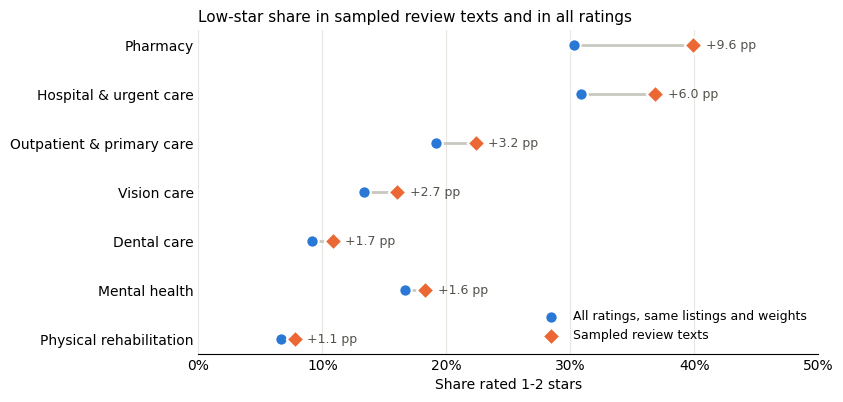

In [19]:
# Paired dots per service group, largest gap at the top.
chart_data = representation_table.drop(index="Overall").sort_values("Gap (pp)")
row_positions = np.arange(len(chart_data))
sampled_share = chart_data["Sampled-text low-star share"]
all_ratings_share = chart_data["All-ratings low-star share"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hlines(row_positions, all_ratings_share, sampled_share, color="#c9c8c0", linewidth=2, zorder=1)
ax.scatter(all_ratings_share, row_positions, s=80, color="#2a78d6", edgecolor="white", linewidth=1.5,
           zorder=2, label="All ratings, same listings and weights")
ax.scatter(sampled_share, row_positions, s=80, color="#eb6834", marker="D", edgecolor="white", linewidth=1.5,
           zorder=2, label="Sampled review texts")
for position, share, gap in zip(row_positions, np.maximum(sampled_share, all_ratings_share), chart_data["Gap (pp)"]):
    ax.annotate(f"{gap:+.1f} pp", (share, position), xytext=(9, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514b")

ax.set_yticks(row_positions, chart_data.index)
ax.set_xlim(0, 0.5)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel("Share rated 1-2 stars")
ax.set_title("Low-star share in sampled review texts and in all ratings", loc="left", fontsize=11)
ax.grid(axis="x", color="#e7e6e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
plt.show()

In every service group, the sampled texts hold a larger share of low-star reviews than all ratings at the same listings: 18.6% versus 15.6% overall, a gap of 2.9 percentage points. The gap is largest for pharmacies (39.9% versus 30.3%, 9.6 points), followed by hospitals and urgent care (6.0 points).

The comparison measures how the review sample we can read differs from the full rating record at the same listings. It says nothing about which services give better care. The full distribution includes ratings left without any text, and how and when `top_reviews` was selected and collected is not documented, so the gap cannot be assigned to one cause.

## 5. Text classification

*Planned.* Train TF-IDF features (words and adjacent word pairs) with logistic regression on valid records from Reviews, after removing records that share a `place_id` or identical text with the healthcare evaluation set. The training source will be split by `place_id` into training, validation and test partitions, with validation used for limited tuning and threshold selection.

Review text is the only model input. The baseline is a majority-class classifier fitted on the same training data.

## 6. Where does the model miss low-star reviews?

*Planned.* Once the model is locked, score the Bay Area healthcare reviews. This is an external evaluation set used for descriptive EDA but not for model fitting or tuning. Report macro-F1 and low-star precision, recall and F1 for the baseline and the model on the same reviews.

A table by service group will show reviews, place listings, actual low-star reviews and missed low-star reviews, so a reader can see how many of every 100 low-star reviews the model misses. Missed reviews and false positives will be read by hand and described in anonymous paraphrase.

## 7. Limits and implications

*Planned.* Summarize what the two comparisons show for people who use text tools to organize community feedback, and what they cannot show. Differences between service groups describe model reliability across settings. They are not evidence about care quality, causal sector effects or demographic discrimination.